# Student Performance — Visualization Notebook

Exploratory visualizations built on `student_cleaned.csv` (produced by
`student_analysis.ipynb`). Uses matplotlib and seaborn.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

In [2]:
df = pd.read_csv("student_cleaned.csv")
df.shape

(6564, 22)

In [3]:
# data exploration
print("first five rows: \n", df.head(5))

first five rows: 
    Hours_Studied  attendance Parental Involvement Access_to_Resources  \
0           23.0        66.0                 High                High   
1           16.0        75.0               Medium              Medium   
2           22.0        98.0               Medium              Medium   
3           28.0        76.0               Medium                High   
4           19.0        76.0                 High                 Low   

  ExtracurricularActivities  Sleep_hours  Previous_Scores motivation_level  \
0                       Yes          7.0               80           Medium   
1                       Yes          8.0               94           Medium   
2                       Yes          6.0               93           Medium   
3                       Yes          6.0               75             High   
4                       Yes          9.0               78              Low   

  Internet_Access  Tutoring_Sessions  ... School_Type Peer_Influence  \
0

In [4]:
print(f"Exam score range is {df['Exam_Score'].min()} to {df['Exam_Score'].max()}")
print(f"Average exam score is {df['Exam_Score'].mean():.2f}")

Exam score range is 55.0 to 100.0
Average exam score is 67.24


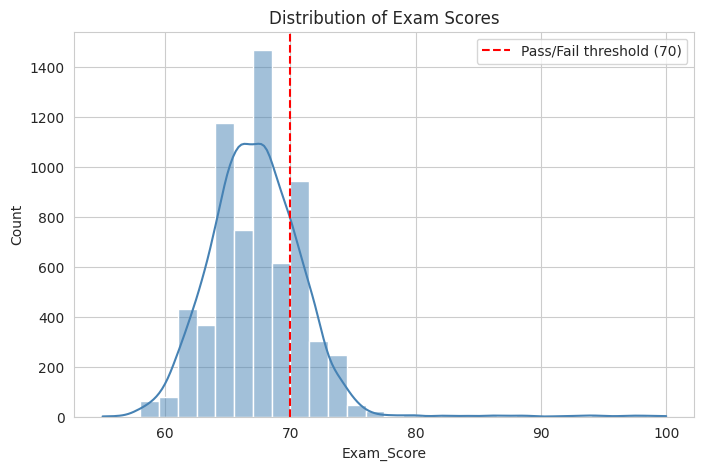

In [5]:
# Exam score distribution
plt.figure(figsize=(8, 5))
sns.histplot(df["Exam_Score"], bins=30, kde=True, color="steelblue")
plt.axvline(70, color="red", linestyle="--", label="Pass/Fail threshold (70)")
plt.title("Distribution of Exam Scores")
plt.legend()
plt.show()

In [6]:
score_by_involvement = df.groupby("Parental Involvement")["Exam_Score"].mean().reset_index()
print(score_by_involvement)

  Parental Involvement  Exam_Score
0                 High   68.105177
1                  Low   66.356529
2               Medium   67.104348


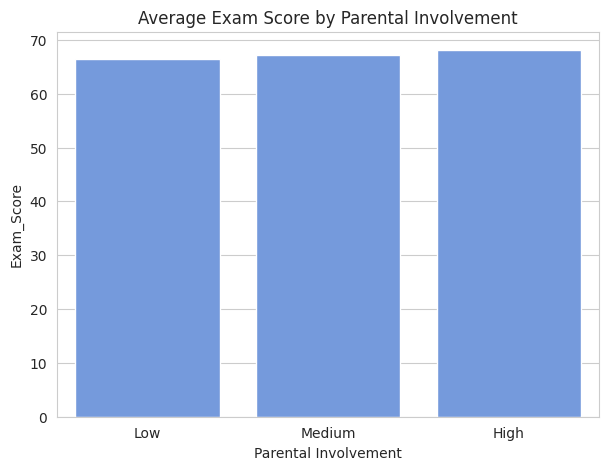

In [7]:
plt.figure(figsize=(7, 5))
sns.barplot(x="Parental Involvement", y="Exam_Score", data=score_by_involvement,
            order=["Low", "Medium", "High"], color="cornflowerblue")
plt.title("Average Exam Score by Parental Involvement")
plt.show()

In [8]:
score_by_resources = df.groupby("Access_to_Resources")["Exam_Score"].mean().reset_index()
print(score_by_resources)

  Access_to_Resources  Exam_Score
0                High   68.102904
1                 Low   66.207055
2              Medium   67.131635


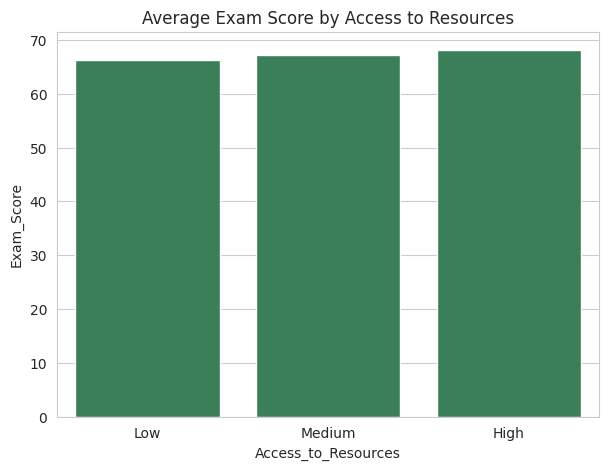

In [9]:
plt.figure(figsize=(7, 5))
sns.barplot(x="Access_to_Resources", y="Exam_Score", data=score_by_resources,
            order=["Low", "Medium", "High"], color="seagreen")
plt.title("Average Exam Score by Access to Resources")
plt.show()

In [10]:
score_by_teacher = df.groupby("Teacher_Quality")["Exam_Score"].mean().reset_index()
print(score_by_teacher)

  Teacher_Quality  Exam_Score
0            High   67.664832
1             Low   66.805601
2          Medium   67.114734


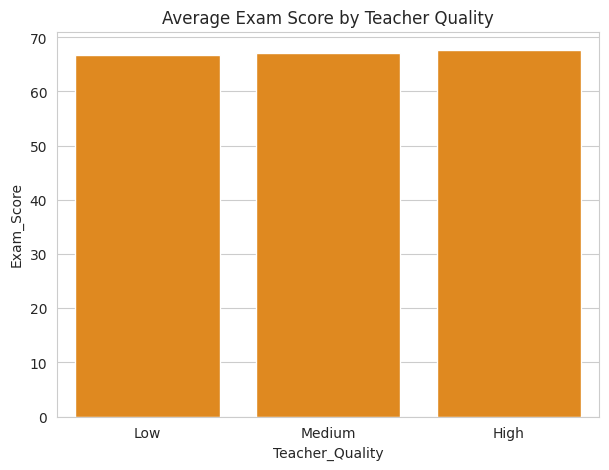

In [11]:
plt.figure(figsize=(7, 5))
sns.barplot(x="Teacher_Quality", y="Exam_Score", data=score_by_teacher,
            order=["Low", "Medium", "High"], color="darkorange")
plt.title("Average Exam Score by Teacher Quality")
plt.show()

In [12]:
Q1 = df["Hours_Studied"].quantile(0.25)
Q3 = df["Hours_Studied"].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR
lower_bound = Q1 - 1.5 * IQR
print(f"Hours_Studied outlier bounds: [{lower_bound:.1f}, {upper_bound:.1f}]")

Hours_Studied outlier bounds: [4.0, 36.0]


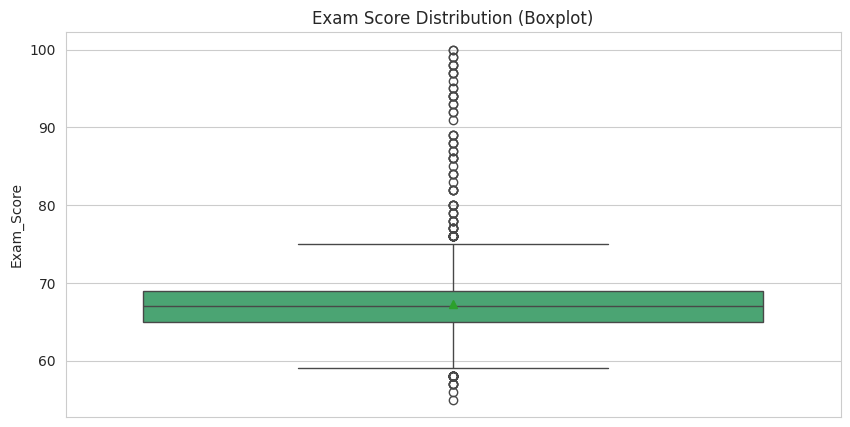

In [13]:
plt.figure(figsize=(10, 5))
sns.boxplot(y="Exam_Score", data=df, color="mediumseagreen", showmeans=True)
plt.title("Exam Score Distribution (Boxplot)")
plt.show()

In [14]:
exam_q1 = df["Exam_Score"].quantile(0.25)
exam_q3 = df["Exam_Score"].quantile(0.75)
exam_iqr = exam_q3 - exam_q1
print(f"Exam score IQR: {exam_iqr:.2f} (Q1={exam_q1}, Q3={exam_q3})")

Exam score IQR: 4.00 (Q1=65.0, Q3=69.0)


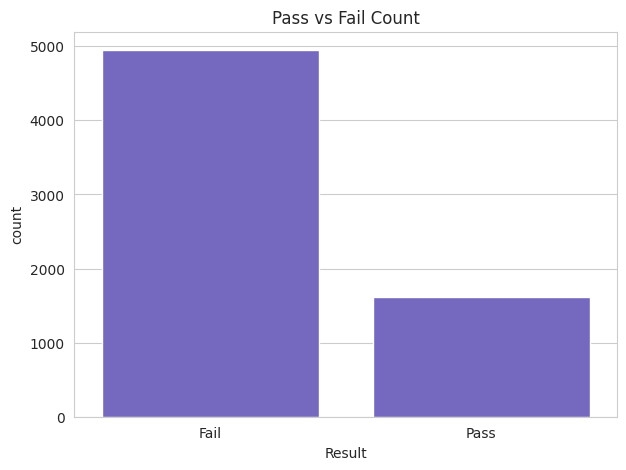

In [15]:
result_order = df["Result"].value_counts().index

plt.figure(figsize=(7, 5))
sns.countplot(x="Result", data=df, order=result_order, color="slateblue")
plt.title("Pass vs Fail Count")
plt.show()

In [16]:
result_count = df["Result"].value_counts()
print(result_count)
print()
print("1. Result with more students:", result_count.idxmax())
print("2. Overall pass rate:", f"{(df['Result']=='Pass').mean()*100:.1f}%")

Result
Fail    4948
Pass    1616
Name: count, dtype: int64

1. Result with more students: Fail
2. Overall pass rate: 24.6%


In [17]:
avg_hours_by_result = df.groupby("Result")["Hours_Studied"].mean().reset_index()
print(avg_hours_by_result)

  Result  Hours_Studied
0   Fail      18.740501
1   Pass      23.801980


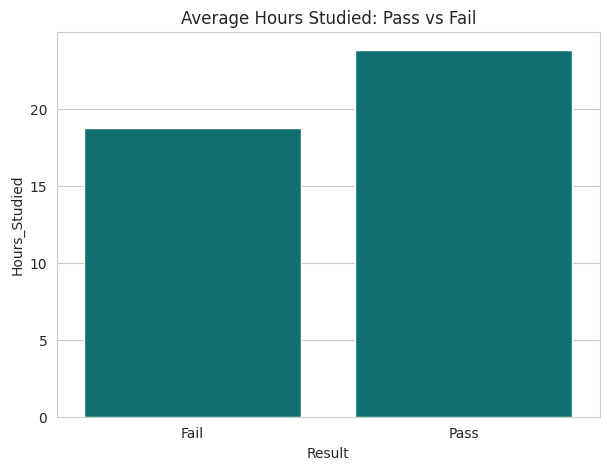

In [18]:
plt.figure(figsize=(7, 5))
sns.barplot(x="Result", y="Hours_Studied", data=avg_hours_by_result, color="teal")
plt.title("Average Hours Studied: Pass vs Fail")
plt.show()

In [19]:
highest_avg_hours = avg_hours_by_result.sort_values(by="Hours_Studied", ascending=False).iloc[0]
print(f"Group that studies more on average: {highest_avg_hours['Result']} "
      f"({highest_avg_hours['Hours_Studied']:.1f} hrs/week)")

Group that studies more on average: Pass (23.8 hrs/week)


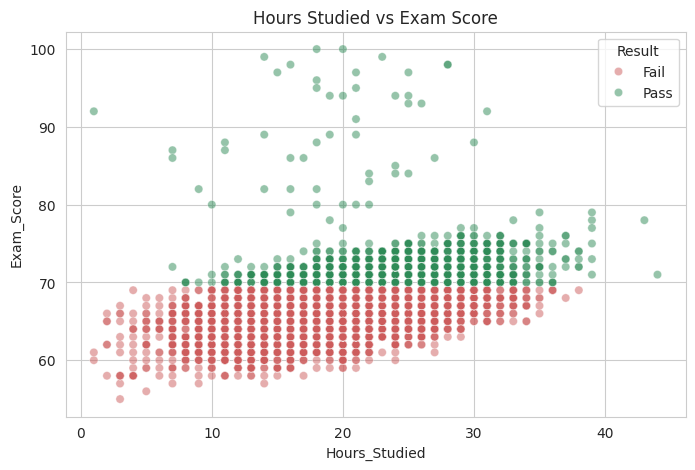

In [20]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x="Hours_Studied", y="Exam_Score", data=df, hue="Result", alpha=0.5,
                 palette={"Pass": "seagreen", "Fail": "indianred"})
plt.title("Hours Studied vs Exam Score")
plt.show()

In [21]:
hours_score_corr = df["Hours_Studied"].corr(df["Exam_Score"])
attendance_score_corr = df["attendance"].corr(df["Exam_Score"])
print(f"Correlation (Hours Studied, Exam Score): {hours_score_corr:.3f}")
print(f"Correlation (Attendance, Exam Score): {attendance_score_corr:.3f}")

Correlation (Hours Studied, Exam Score): 0.436
Correlation (Attendance, Exam Score): 0.576


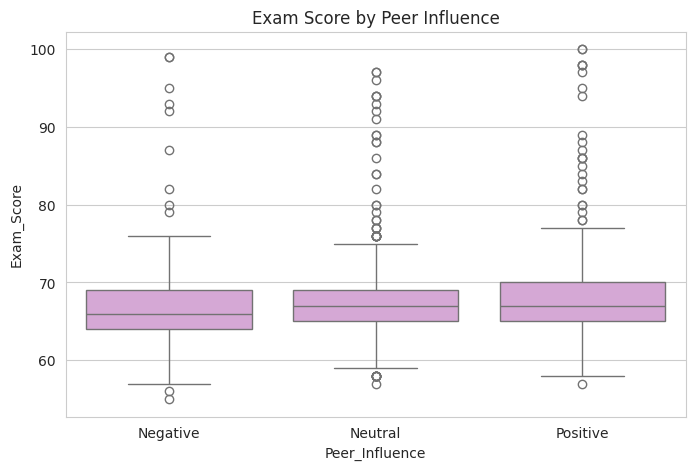

In [22]:
plt.figure(figsize=(8, 5))
sns.boxplot(x="Peer_Influence", y="Exam_Score", data=df,
            order=["Negative", "Neutral", "Positive"], color="plum")
plt.title("Exam Score by Peer Influence")
plt.show()

In [23]:
score_variation_by_school = df.groupby("School_Type")["Exam_Score"].std()
pass_rate_by_school = df.groupby("School_Type")["Result"].apply(lambda s: (s == "Pass").mean() * 100)
print("Exam score std. dev by school type:")
print(score_variation_by_school)
print()
print("Pass rate (%) by school type:")
print(pass_rate_by_school)

Exam score std. dev by school type:
School_Type
Private    3.848199
Public     3.910943
Name: Exam_Score, dtype: float64

Pass rate (%) by school type:
School_Type
Private    25.037556
Public     24.436173
Name: Result, dtype: float64


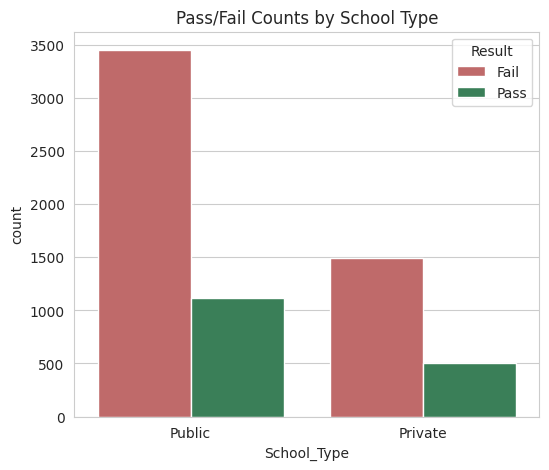

In [24]:
plt.figure(figsize=(6, 5))
sns.countplot(x="School_Type", hue="Result", data=df,
              palette={"Pass": "seagreen", "Fail": "indianred"})
plt.title("Pass/Fail Counts by School Type")
plt.show()

In [25]:
performance_band_count = df["Performance_Band"].value_counts()
print(performance_band_count)

Performance_Band
Needs Improvement    4948
Average              1568
Good                   26
Excellent              22
Name: count, dtype: int64


In [26]:
num_cols = df.select_dtypes(include="number")
corr = num_cols.corr()
print(corr)

                   Hours_Studied  attendance  Sleep_hours  Previous_Scores  \
Hours_Studied           1.000000   -0.010985     0.013523         0.022740   
attendance             -0.010985    1.000000    -0.013699        -0.017840   
Sleep_hours             0.013523   -0.013699     1.000000        -0.022364   
Previous_Scores         0.022740   -0.017840    -0.022364         1.000000   
Tutoring_Sessions      -0.012527    0.013979    -0.013648        -0.013494   
Physical_Activity       0.002319   -0.023556    -0.000126        -0.012808   
Exam_Score              0.436457    0.576064    -0.015133         0.175182   

                   Tutoring_Sessions  Physical_Activity  Exam_Score  
Hours_Studied              -0.012527           0.002319    0.436457  
attendance                  0.013979          -0.023556    0.576064  
Sleep_hours                -0.013648          -0.000126   -0.015133  
Previous_Scores            -0.013494          -0.012808    0.175182  
Tutoring_Sessions        

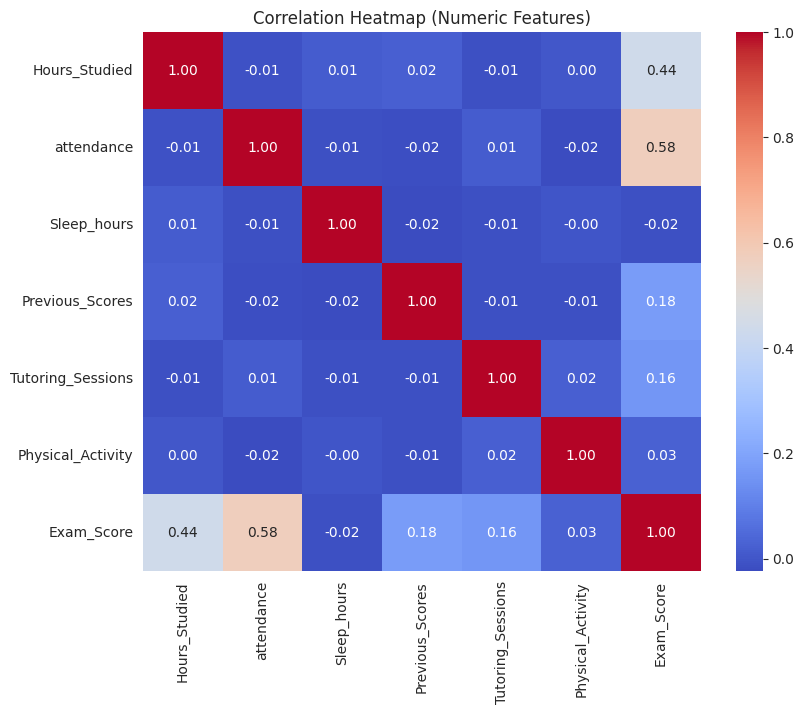

In [27]:
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap (Numeric Features)")
plt.show()

In [28]:
print("1. Hours_Studied and Attendance are positively correlated with Exam_Score")
print("2. Sleep_hours and Physical_Activity show only weak correlation with Exam_Score")
print("3. Previous_Scores has a meaningful positive relationship with Exam_Score")

1. Hours_Studied and Attendance are positively correlated with Exam_Score
2. Sleep_hours and Physical_Activity show only weak correlation with Exam_Score
3. Previous_Scores has a meaningful positive relationship with Exam_Score


In [29]:
highest_avg_score_category = df.groupby("motivation_level")["Exam_Score"].mean().idxmax()
highest_pass_rate_category = df.groupby("motivation_level")["Result"].apply(
    lambda s: (s == "Pass").mean()
).idxmax()
print("Motivation level with highest average exam score:", highest_avg_score_category)
print("Motivation level with highest pass rate:", highest_pass_rate_category)

Motivation level with highest average exam score: High
Motivation level with highest pass rate: High


In [30]:
print("1. Student performance data shows clear study-habit and support-factor patterns")
print("2. Hours studied, attendance, and previous scores are the strongest predictors of Exam_Score")
print("3. Parental involvement, access to resources, and teacher quality show a mild positive")
print("   relationship with performance, useful as supporting features for the model")

1. Student performance data shows clear study-habit and support-factor patterns
2. Hours studied, attendance, and previous scores are the strongest predictors of Exam_Score
3. Parental involvement, access to resources, and teacher quality show a mild positive
   relationship with performance, useful as supporting features for the model


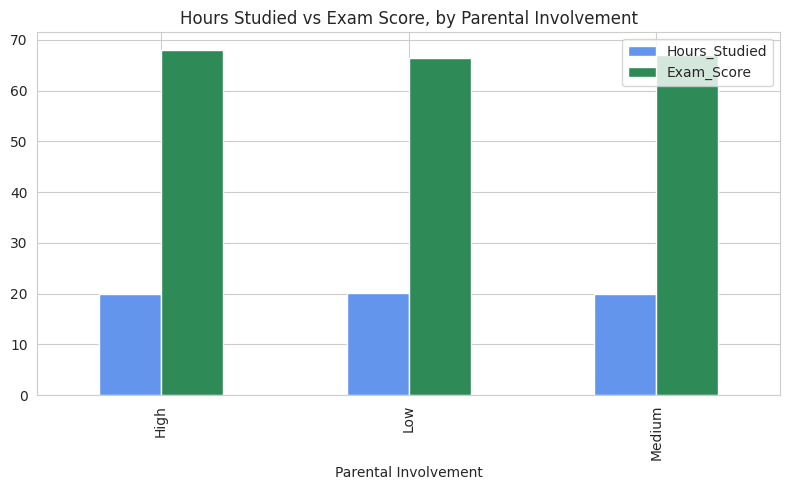

In [31]:
involvement_comparison = df.groupby("Parental Involvement")[["Hours_Studied", "Exam_Score"]].mean().reset_index()
involvement_comparison.plot(x="Parental Involvement", y=["Hours_Studied", "Exam_Score"],
                             kind="bar", figsize=(8, 5), color=["cornflowerblue", "seagreen"])
plt.title("Hours Studied vs Exam Score, by Parental Involvement")
plt.tight_layout()
plt.show()